# Practice 05 — AutoML

**Goal:** let three tools answer *which model, with which hyperparameters?*

| Section | Searched | With |
|:---|:---|:---|
| 1 | one hyperparameter | a `for` loop |
| 2 | two hyperparameters | `GridSearchCV` |
| 3 | the model family as well | `GridSearchCV`, Optuna, FLAML |

- Install → `pip install optuna flaml lightgbm` (not `flaml[automl]`, which downgrades XGBoost)

---
## Imports and Data

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # must be set before sklearn is imported

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning

import optuna
from optuna.visualization.matplotlib import plot_contour
from flaml import AutoML

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
np.random.seed(42)

In [2]:
digits = load_digits()

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=42, stratify=digits.target)

n_classes = len(np.unique(digits.target))

print(f'train   {X_train.shape}')
print(f'test    {X_test.shape}')
print(f'classes {n_classes}')

train   (1437, 64)
test    (360, 64)
classes 10


---
## Pipeline

- `make_pipeline` → preprocessing + model as one estimator with the usual `fit` / `predict`
- Refitted inside every cross-validation fold → the scaler sees only that fold's training part

In [3]:
example = make_pipeline(StandardScaler(), SVC(random_state=42))
print('auto-named steps:', list(example.named_steps))

auto-named steps: ['standardscaler', 'svc']


- `make_pipeline` names each step after its class → `standardscaler`, `svc`

### A Fixed Step Name

- **Swapping the model** in a search needs a fixed step name → `Pipeline` written out, with a `'model'` step
- Parameters → `stepname__parametername`, here `model__C`

In [4]:
pipeline = Pipeline([('scaler', StandardScaler()),
                     ('model',  SVC(random_state=42))])   # placeholder, replaced by the search
print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC(random_state=42))])


---
## Evaluation — Cross-Validation

- Training set in $k$ parts → fit $k$ times, each time holding out a different part → average the $k$ held-out scores
- Written as a loop first

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_scores = []
for train_index, valid_index in cv.split(X_train, y_train):
    model = clone(pipeline)                                   # a fresh, unfitted copy
    model.fit(X_train[train_index], y_train[train_index])
    y_pred_fold = model.predict(X_train[valid_index])
    fold_scores.append(accuracy_score(y_train[valid_index], y_pred_fold))

### The Same Loop in One Call

- `cross_val_score` → given the same `cv` object, it runs the loop above

In [6]:
scores = cross_val_score(pipeline, X_train, y_train, cv=cv)
mean_score = np.mean(scores)
mean_score_manual = np.mean(fold_scores)

print('fold scores         :', np.round(scores, 4))
print('fold scores (manual):', np.round(fold_scores, 4))
print(f'mean          {mean_score:.4f}')
print(f'mean (manual) {mean_score_manual:.4f}')

fold scores         : [0.9861 0.9757 0.9861 0.9721 0.9861]
fold scores (manual): [0.9861 0.9757 0.9861 0.9721 0.9861]
mean          0.9812
mean (manual) 0.9812


---
# 1. One Hyperparameter — a Sweep

- SVC's `C` → penalty for misclassifying a training point
- Small `C` → smooth boundary, large `C` → tries to fit every point
- Each value is scored by the same `cv`; `gamma` stays at its default (`'scale'`)

In [7]:
C_values = [0.01, 0.1, 1, 10, 100, 1000]
sweep_scores = []

for C in C_values:
    candidate = Pipeline([('scaler', StandardScaler()), ('model', SVC(C=C, random_state=42))])
    candidate_scores = cross_val_score(candidate, X_train, y_train, cv=cv, n_jobs=-1)
    mean_score = np.mean(candidate_scores)
    sweep_scores.append(mean_score)
    print(f'C = {C:7g}   5-fold CV accuracy = {mean_score:.4f}')

C =    0.01   5-fold CV accuracy = 0.1601


C =     0.1   5-fold CV accuracy = 0.9262


C =       1   5-fold CV accuracy = 0.9812


C =      10   5-fold CV accuracy = 0.9798


C =     100   5-fold CV accuracy = 0.9798


C =    1000   5-fold CV accuracy = 0.9798


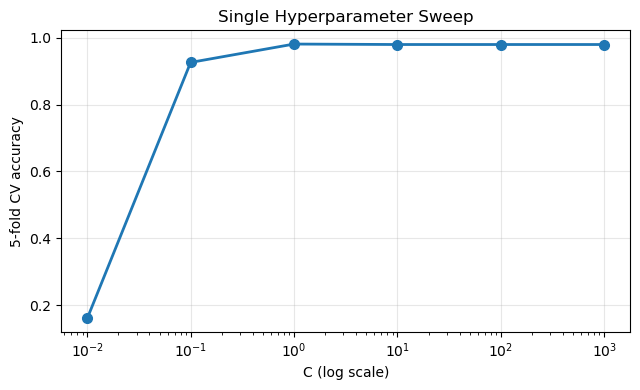

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(C_values, sweep_scores, 'o-', linewidth=2, markersize=7)
ax.set_xlabel('C (log scale)')
ax.set_ylabel('5-fold CV accuracy')
ax.set_title('Single Hyperparameter Sweep')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Steep climb, then flat → every `C` from 1 upward scores 0.98
- A sweep answers one question → where does this parameter stop mattering?

---
# 2. Two Hyperparameters — a Grid

- `gamma` → how far the influence of one training point reaches
- Interacts with `C` → a good `C` at one `gamma` is bad at another: tune them together
- `GridSearchCV` → every combination: 4 x 4 = 16, each fitted 5 times

In [9]:
param_grid = {'model__C': [0.1, 1, 10, 100], 'model__gamma': [1e-4, 1e-3, 1e-2, 1e-1]}

grid_two = GridSearchCV(pipeline, param_grid, cv=cv, n_jobs=-1)
grid_two.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', SVC(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__C': [0.1, 1, 10, 100],
                         'model__gamma': [0.0001, 0.001, 0.01, 0.1]})

### Every Candidate

- `cv_results_` → everything the search tried, one row per candidate

In [10]:
results_two = pd.DataFrame(grid_two.cv_results_)

display(results_two[['param_model__C', 'param_model__gamma',
                     'mean_test_score', 'std_test_score', 'rank_test_score']].round(4))

print('best params :', grid_two.best_params_)
print(f'best CV     : {grid_two.best_score_:.4f}')

,param_model__C,param_model__gamma,mean_test_score,std_test_score,rank_test_score
0,0.1,0.0001,0.1553,0.0446,16
1,0.1,0.0010,0.4906,0.0173,14
2,0.1,0.0100,0.9262,0.0143,12
3,0.1,0.1000,0.3458,0.0356,15
4,1.0,0.0001,0.5755,0.0072,13
5,1.0,0.0010,0.9443,0.0079,8
6,1.0,0.0100,0.9784,0.0080,3
7,1.0,0.1000,0.9311,0.0135,11
8,10.0,0.0001,0.9457,0.0068,7
9,10.0,0.0010,0.9756,0.0134,6


best params : {'model__C': 10, 'model__gamma': 0.01}
best CV     : 0.9791


- `best_params_` → the first row with `rank_test_score` 1 (rows 10 and 14 tie)

### The Grid as a Map

- The `mean_test_score` column reshaped to 4 x 4 → rows `C`, columns `gamma`

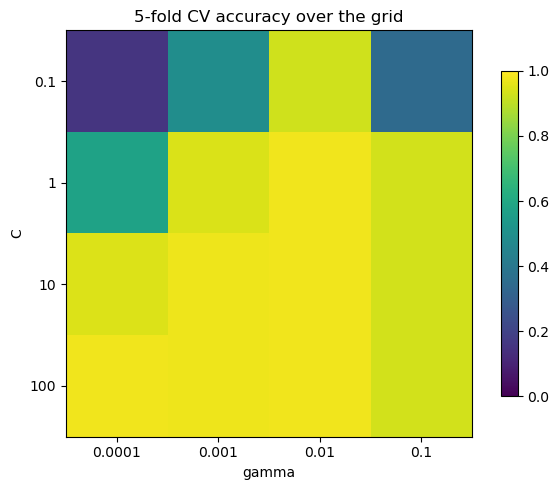

In [11]:
grid_scores = grid_two.cv_results_['mean_test_score'].reshape(4, 4)

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(grid_scores, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(4), param_grid['model__gamma'])
ax.set_yticks(range(4), param_grid['model__C'])
ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title('5-fold CV accuracy over the grid')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

- Read the map, not the single best number → `C` matters most at small `gamma`: at 0.0001, 0.16 (`C` = 0.1) to 0.98 (`C` = 100); at 0.01, flat at 0.98 from `C` = 1
- Grid best 0.9791 < sweep 0.9812 → the sweep's default `gamma` ≈ 0.016 lies between two grid columns: a grid tries only what you wrote

---
# 3. The Model as Well

- Two hyperparameters → 16 candidates; five with five values each → 3125
- The model family is not a number → it cannot be put on an axis at all
- Three tools below → the same four families, 20 candidates each

## The Candidates

| Family | Kind | Hyperparameters searched |
|:---|:---|:---|
| Logistic Regression | linear | `C` |
| KNN | distance-based | `n_neighbors` |
| SVC | kernel machine | `C`, `gamma` |
| Random Forest | tree ensemble | `n_estimators`, `max_depth` |

---
## `GridSearchCV`

- A **list of dictionaries** → several models searched in one call
- Each dictionary fixes the `model` step and lists that family's hyperparameters

Documentation: <https://scikit-learn.org/stable/modules/grid_search.html>

In [12]:
search_space = [
    {'model': [LogisticRegression(max_iter=2000, random_state=42)],
     'model__C': [0.1, 1, 10]},
    {'model': [KNeighborsClassifier()],
     'model__n_neighbors': [1, 3, 5, 7]},
    {'model': [SVC(random_state=42)],
     'model__C': [1, 10, 100], 'model__gamma': [1e-3, 1e-2, 1e-1]},
    {'model': [RandomForestClassifier(random_state=42)],
     'model__n_estimators': [100, 300], 'model__max_depth': [None, 10]},
]

grid_search = GridSearchCV(pipeline, search_space, cv=cv, n_jobs=-1)

start = time.time()
grid_search.fit(X_train, y_train)
grid_seconds = time.time() - start

print('candidates :', len(grid_search.cv_results_['params']))
print(f'seconds    : {grid_seconds:.1f}')

candidates : 20
seconds    : 1.1


### One Candidate

- The estimator is now a parameter value → a candidate's `params` holds the model and only that family's hyperparameters

In [13]:
print(grid_search.cv_results_['params'][3])

{'model': KNeighborsClassifier(), 'model__n_neighbors': 1}


### The Winner

- The search already knows which candidate won and refitted it on the whole training set → nothing to compute

In [14]:
grid_test = accuracy_score(y_test, grid_search.predict(X_test))

print('best params :', grid_search.best_params_)
print(f'CV          : {grid_search.best_score_:.4f}')
print(f'test        : {grid_test:.4f}')

best params : {'model': SVC(random_state=42), 'model__C': 10, 'model__gamma': 0.01}
CV          : 0.9791
test        : 0.9833


---
## Optuna

- Nothing is listed → you write a function that scores **one** candidate
- Optuna calls it 20 times, with values of its own choosing

Documentation: <https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/001_first.html>

### `trial`, and What Is Ours

- One call of the objective = one **trial**; `trial` is how Optuna passes values in
- `trial.suggest_float('svc_C', 1e-1, 1e3, log=True)` → returns a value, recorded under that name

| Name | Whose |
|:---|:---|
| `trial`, `suggest_categorical`, `suggest_float`, `suggest_int` | Optuna's |
| `objective`, `family`, `'svc_C'`, `'knn_n_neighbors'` | ours |

- `'family'` → an ordinary categorical parameter; its branch decides which parameters are asked next

In [15]:
def objective(trial):
    family = trial.suggest_categorical(
        'family', ['LogisticRegression', 'KNeighborsClassifier', 'SVC', 'RandomForestClassifier'])

    if family == 'LogisticRegression':
        C = trial.suggest_float('logistic_C', 1e-2, 1e2, log=True)
        model = LogisticRegression(C=C, max_iter=2000, random_state=42)
    elif family == 'KNeighborsClassifier':
        n_neighbors = trial.suggest_int('knn_n_neighbors', 1, 15)
        model = KNeighborsClassifier(n_neighbors=n_neighbors)
    elif family == 'SVC':
        C = trial.suggest_float('svc_C', 1e-1, 1e3, log=True)
        gamma = trial.suggest_float('svc_gamma', 1e-4, 1e0, log=True)
        model = SVC(C=C, gamma=gamma, random_state=42)
    else:
        n_estimators = trial.suggest_int('rf_n_estimators', 50, 400, step=50)
        max_depth = trial.suggest_categorical('rf_max_depth', [None, 10, 20])
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)

    candidate = Pipeline([('scaler', StandardScaler()), ('model', model)])
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, n_jobs=-1)
    return np.mean(scores)


start = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20)
optuna_seconds = time.time() - start

print('trials  :', len(study.trials))
print(f'seconds : {optuna_seconds:.1f}')

trials  : 20
seconds : 1.5


### Reading the Study

- `study` keeps all 20 trials, not only the winner → where did the budget go?

In [16]:
for trial in study.trials:
    print(f'trial {trial.number:2d}   {trial.params["family"]:24s} {trial.value:.4f}')

trial  0   KNeighborsClassifier     0.9763
trial  1   SVC                      0.9763
trial  2   LogisticRegression       0.9582
trial  3   KNeighborsClassifier     0.9659
trial  4   RandomForestClassifier   0.9742
trial  5   KNeighborsClassifier     0.9596
trial  6   LogisticRegression       0.9694
trial  7   SVC                      0.9756
trial  8   LogisticRegression       0.9582
trial  9   LogisticRegression       0.9708
trial 10   SVC                      0.9033
trial 11   KNeighborsClassifier     0.9694
trial 12   SVC                      0.1051
trial 13   RandomForestClassifier   0.9743
trial 14   KNeighborsClassifier     0.9694
trial 15   SVC                      0.9687
trial 16   SVC                      0.9791
trial 17   SVC                      0.9791
trial 18   SVC                      0.9805
trial 19   SVC                      0.9798


- Uneven budget → SVC 9 trials, Random Forest 2
- Optuna returns to what scored well; a grid fixes its allocation before any result

### The SVC Trials as a Map

- The nine SVC trials vary `C` and `gamma`, like the grid heatmap above → here `C` is on the horizontal axis

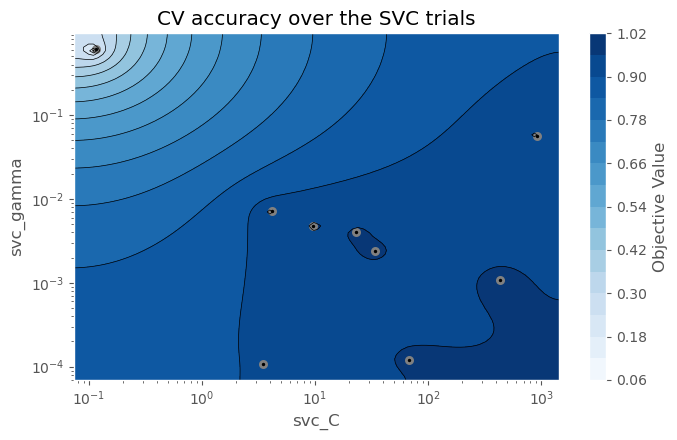

In [17]:
ax = plot_contour(study, params=['svc_C', 'svc_gamma'])
ax.set_title('CV accuracy over the SVC trials')
ax.figure.set_size_inches(7, 4.5)
plt.tight_layout()
plt.show()

- Grid → one point per cell; Optuna → one visit to the bad corner (small `C`, large `gamma`), eight elsewhere scoring 0.90 to 0.98
- Colour is measured only at the markers → between them it is interpolated

### Rebuilding the Winner

- `study.best_params` → one flat dictionary; the prefixes keep `svc_C` and `logistic_C` apart
- The search fitted nothing on the full training set → rebuild the winner and fit it here (`GridSearchCV` did this for us)

In [18]:
best_params = study.best_params
print('best params :', best_params)

if best_params['family'] == 'LogisticRegression':
    best_model = LogisticRegression(C=best_params['logistic_C'], max_iter=2000, random_state=42)
elif best_params['family'] == 'KNeighborsClassifier':
    best_model = KNeighborsClassifier(n_neighbors=best_params['knn_n_neighbors'])
elif best_params['family'] == 'SVC':
    best_model = SVC(C=best_params['svc_C'], gamma=best_params['svc_gamma'], random_state=42)
else:
    best_model = RandomForestClassifier(n_estimators=best_params['rf_n_estimators'],
                                        max_depth=best_params['rf_max_depth'], random_state=42)

optuna_model = Pipeline([('scaler', StandardScaler()), ('model', best_model)])
optuna_model.fit(X_train, y_train)
optuna_test = accuracy_score(y_test, optuna_model.predict(X_test))

print(f'CV          : {study.best_value:.4f}')
print(f'test        : {optuna_test:.4f}')

best params : {'family': 'SVC', 'svc_C': 9.641958295232145, 'svc_gamma': 0.004716733098882283}
CV          : 0.9805
test        : 0.9833


---
## FLAML

- `estimator_list` names the families → the rest is FLAML's: hyperparameter ranges, its own 5 folds, no scaler
- `max_iter` instead of `time_budget` → the run does not depend on machine speed
- FLAML's `svc` is a linear SVM → close to, but not the same as, the RBF `SVC` above

Documentation, with the full list of built-in estimators: <https://microsoft.github.io/FLAML/docs/Use-Cases/Task-Oriented-AutoML>

In [19]:
start = time.time()
automl_listed = AutoML()
automl_listed.fit(X_train=X_train, y_train=y_train, task='classification', metric='accuracy',
                  estimator_list=['lrl2', 'kneighbor', 'svc', 'rf'],   # FLAML's names for the four families
                  eval_method='cv', n_splits=5, max_iter=20, time_budget=-1, seed=42, verbose=0)
flaml_seconds = time.time() - start

print('best CV accuracy per family, as FLAML reports it:')
for family, loss in automl_listed.best_loss_per_estimator.items():
    accuracy = 1 - loss                                   # FLAML reports loss = 1 - accuracy
    print(f'  {family:12s} {accuracy:.4f}')

best CV accuracy per family, as FLAML reports it:
  lrl2         0.9631
  kneighbor    0.9882
  svc          0.9478
  rf           0.6729


- `rf` 0.67, far below the other three → an unsuitable family, or one that was barely tried?

In [20]:
flaml_cv = 1 - automl_listed.best_loss
flaml_test = accuracy_score(y_test, automl_listed.predict(X_test))

print('best estimator :', automl_listed.best_estimator)
print('best config    :', automl_listed.best_config)
print(f'CV             : {flaml_cv:.4f}')
print(f'test           : {flaml_test:.4f}')
print(f'seconds        : {flaml_seconds:.1f}')

best estimator : kneighbor
best config    : {'n_neighbors': 1}
CV             : 0.9882
test           : 0.9861
seconds        : 6.1


- FLAML's winner → KNN with a single neighbour (`n_neighbors=1`)

### Without `estimator_list`

- The list was only there to match the other two tools → left out, FLAML searches its default catalogue
- Held fixed → data, 5-fold CV, 20 iterations

In [21]:
start = time.time()
automl_default = AutoML()
automl_default.fit(X_train=X_train, y_train=y_train, task='classification', metric='accuracy',
                   eval_method='cv', n_splits=5, max_iter=20, time_budget=-1, seed=42, verbose=0)
default_seconds = time.time() - start

print('families FLAML chose for itself:')
for family, loss in automl_default.best_loss_per_estimator.items():
    accuracy = 1 - loss
    print(f'  {family:16s} {accuracy:.4f}')

families FLAML chose for itself:
  lgbm             0.9450
  rf               0.5998
  xgboost          0.9012
  extra_tree       0.6562
  xgb_limitdepth   0.9360
  sgd              0.8866
  lrl1             0.9610


In [22]:
default_cv = 1 - automl_default.best_loss
default_test = accuracy_score(y_test, automl_default.predict(X_test))

print('best estimator :', automl_default.best_estimator)
print(f'CV             : {default_cv:.4f}')
print(f'test           : {default_test:.4f}')
print(f'seconds        : {default_seconds:.1f}')

best estimator : lrl1
CV             : 0.9610
test           : 0.9667
seconds        : 6.1


- More families, lower score → 0.99 to 0.96
- Different catalogue → built around gradient boosting, no KNN, no SVC

### Random Forest Alone

- `max_iter=20` is the total, shared by seven families → the Random Forest gets few steps to grow its trees
- Same Random Forest, same 20 iterations, the whole budget to one family

In [23]:
automl_rf_only = AutoML()
automl_rf_only.fit(X_train=X_train, y_train=y_train, task='classification', metric='accuracy',
                   estimator_list=['rf'],
                   eval_method='cv', n_splits=5, max_iter=20, time_budget=-1, seed=42, verbose=0)

rf_shared_with_six   = 1 - automl_default.best_loss_per_estimator['rf']
rf_shared_with_three = 1 - automl_listed.best_loss_per_estimator['rf']
rf_alone             = 1 - automl_rf_only.best_loss

print(f'sharing with 6 others : {rf_shared_with_six:.4f}')
print(f'sharing with 3 others : {rf_shared_with_three:.4f}')
print(f'alone                 : {rf_alone:.4f}')

print('config, shared :', automl_default.best_config_per_estimator['rf'])
print('config, alone  :', automl_rf_only.best_config)

sharing with 6 others : 0.5998
sharing with 3 others : 0.6729
alone                 : 0.9353
config, shared : {'n_estimators': 5, 'max_features': 0.1, 'max_leaves': 4, 'criterion': np.str_('entropy')}
config, alone  : {'n_estimators': 13, 'max_features': 0.1, 'max_leaves': 53, 'criterion': np.str_('entropy')}


- Random Forest → 0.60 shared with six others, 0.94 alone: the 0.60 measured the budget, not the family
- Shared → 5 trees of at most 4 leaves, too small for 10 classes; alone → 13 trees of up to 53 leaves
- Unfamiliar data → leave the list out, raise `max_iter`

---
## Comparison

- The three searches over the same four families, 20 candidates each

In [24]:
print('GridSearchCV')
print(f'  CV      {grid_search.best_score_:.4f}')
print(f'  test    {grid_test:.4f}')
print(f'  seconds {grid_seconds:.1f}')

print('Optuna')
print(f'  CV      {study.best_value:.4f}')
print(f'  test    {optuna_test:.4f}')
print(f'  seconds {optuna_seconds:.1f}')

print('FLAML')
print(f'  CV      {flaml_cv:.4f}')
print(f'  test    {flaml_test:.4f}')
print(f'  seconds {flaml_seconds:.1f}')

GridSearchCV
  CV      0.9791
  test    0.9833
  seconds 1.1
Optuna
  CV      0.9805
  test    0.9833
  seconds 1.5
FLAML
  CV      0.9882
  test    0.9861
  seconds 6.1


- CV → not like-for-like: FLAML used its own folds and no scaler, so compare on test
- Test accuracy 0.983 / 0.983 / 0.986 → one test sample apart: a tie, not a ranking
- Grid → its 20 candidates were fixed in advance; adaptive searches → moved their 20 to what was working

---
## Summary

| | You write | It decides |
|:---|:---|:---|
| `GridSearchCV` | every candidate | nothing — it runs them all |
| Optuna | an objective function | which candidate to try next |
| FLAML | family names, or nothing | families if unnamed, ranges, next candidate |

- CV scores compare only on the same folds and preprocessing → otherwise use the test set
- Read per-family scores before the winner → low can mean "barely tried", not "unsuitable"
- One test sample apart → a tie, not a ranking